# Evaluar más allá de la exactitud: la lección de Made With ML

`04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta` terminó con un número: 97.72% de exactitud en la prueba. Es un buen número, pero responde una sola pregunta. No dice en qué dígitos falla el modelo, ni si se equivoca más con cierta letra o cierto tipo de trazo, ni si se puede confiar en la probabilidad que entrega, ni qué hace con una imagen un poco movida.

El curso **Made With ML**, de Goku Mohandas, dedica una lección entera a esas preguntas: *Evaluating ML Models*. La lección usa un clasificador de textos. Este notebook sigue sus secciones en el mismo orden, con un clasificador de MNIST:

- métricas **gruesas** (una para todo el conjunto) y **finas** (una por clase);
- los ejemplos detrás de la **matriz de confusión**;
- **confianza**: si las probabilidades están calibradas, y qué etiquetas de la prueba parecen estar mal puestas;
- **rebanadas** (*slices*): subconjuntos de los datos donde el modelo rinde distinto;
- **interpretabilidad**: qué partes de la imagen usa el modelo;
- **pruebas de comportamiento**: invariancia, direccionales y de funcionalidad mínima;
- **capacidad contra alineación**: por qué la pérdida y la exactitud pueden ir en direcciones opuestas.

En el camino comprobamos con los datos una contradicción entre la página oficial de MNIST y un artículo de 2019 sobre de dónde salen las imágenes de prueba.

El notebook tarda menos de un minuto en una CPU.

**Contenido**

1. Preparación
2. Métricas gruesas
3. Métricas finas
4. Detrás de la matriz de confusión
5. Confianza: calibración
6. Confianza: etiquetas sospechosas
7. Rebanadas
8. Interpretabilidad
9. Pruebas de comportamiento
10. Capacidad contra alineación
11. Evaluar en producción
12. Resumen y ejercicios

## 1. Preparación

El modelo es como el de `01_mnist_de_punta_a_punta`, con una capa oculta de 256 neuronas en lugar de 128: Adam con tasa 0.001 y lotes de 64. Lo entrenamos 10 épocas con 50.000 imágenes, dejamos 10.000 para validación y anotamos la pérdida y la exactitud de validación al final de cada época, que usaremos en la sección 10. Precargamos los datos en memoria para que sea rápido.

In [1]:
import math
import time

import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

print("Versión de PyTorch:", torch.__version__)

MEDIA, DESVIACION = 0.1307, 0.3081
FONDO = (0 - MEDIA) / DESVIACION


def precargar(entrenamiento):
    datos = datasets.MNIST(root="../data", train=entrenamiento, download=True)
    imagenes = ((datos.data.float() / 255 - MEDIA) / DESVIACION).unsqueeze(1)
    return imagenes, datos.targets


X_todo, y_todo = precargar(True)
X_prueba, y_prueba = precargar(False)
orden = torch.randperm(len(X_todo), generator=torch.Generator().manual_seed(0))
X_entrenamiento, y_entrenamiento = X_todo[orden[:50_000]], y_todo[orden[:50_000]]
X_validacion, y_validacion = X_todo[orden[50_000:]], y_todo[orden[50_000:]]

torch.manual_seed(0)
modelo = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
generador = torch.Generator().manual_seed(1)
historia = {"pérdida": [], "exactitud": []}
inicio = time.perf_counter()
for epoca in range(10):
    modelo.train()
    permutacion = torch.randperm(len(X_entrenamiento), generator=generador)
    for i in range(0, len(X_entrenamiento), 64):
        indices = permutacion[i:i + 64]
        perdida = F.cross_entropy(modelo(X_entrenamiento[indices]), y_entrenamiento[indices])
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        logits_validacion = modelo(X_validacion)
    historia["pérdida"].append(F.cross_entropy(logits_validacion, y_validacion).item())
    historia["exactitud"].append((logits_validacion.argmax(dim=1) == y_validacion).float().mean().item())
print(f"entrenado en {time.perf_counter() - inicio:.0f} s; exactitud de validación final: {historia['exactitud'][-1]:.2%}")

Versión de PyTorch: 2.11.0+cpu


entrenado en 27 s; exactitud de validación final: 97.53%


Como en la lección de Made With ML, partimos reuniendo tres cosas sobre la prueba: las etiquetas verdaderas, las predicciones y las probabilidades.

In [2]:
with torch.no_grad():
    logits_prueba = modelo(X_prueba)
probabilidades = logits_prueba.softmax(dim=1)
prediccion = probabilidades.argmax(dim=1)
acierto = prediccion == y_prueba
print(f"exactitud de prueba: {acierto.float().mean():.2%}  ({(~acierto).sum().item()} errores de {len(y_prueba)})")

exactitud de prueba: 97.62%  (238 errores de 10000)


## 2. Métricas gruesas

Para una clase $c$, cada predicción cae en una de estas casillas:

- **verdadero positivo** ($VP_c$): la etiqueta es $c$ y el modelo dijo $c$;
- **falso positivo** ($FP_c$): el modelo dijo $c$, pero la etiqueta era otra;
- **falso negativo** ($FN_c$): la etiqueta era $c$, pero el modelo dijo otra cosa.

Con ellas se definen tres métricas por clase:

$$\text{precisión}_c = \frac{VP_c}{VP_c + FP_c} \qquad \text{exhaustividad}_c = \frac{VP_c}{VP_c + FN_c} \qquad F_1 = \frac{2 \cdot \text{precisión} \cdot \text{exhaustividad}}{\text{precisión} + \text{exhaustividad}}$$

La **precisión** responde "cuando el modelo dice 7, ¿cuántas veces es un 7?". La **exhaustividad** (*recall*) responde "de todos los 7, ¿cuántos encontró?". $F_1$ es su media armónica, que castiga que una de las dos sea baja.

Para resumirlas en un número hay tres promedios: **micro** (sumar las casillas de todas las clases y después dividir), **macro** (promediar las métricas de las clases, todas con el mismo peso) y **ponderado** (promediar con el peso de cuántos ejemplos tiene cada clase). Made With ML usa el ponderado. Las calculamos a mano a partir de la matriz de confusión:

In [3]:
confusion = torch.zeros(10, 10, dtype=torch.long)
confusion.index_put_((y_prueba, prediccion), torch.ones_like(y_prueba), accumulate=True)   # filas: etiqueta

vp = confusion.diag().float()
fp = confusion.sum(dim=0).float() - vp
fn = confusion.sum(dim=1).float() - vp
soporte = confusion.sum(dim=1).float()

precision = vp / (vp + fp)
exhaustividad = vp / (vp + fn)
f1 = 2 * precision * exhaustividad / (precision + exhaustividad)
peso = soporte / soporte.sum()

print(f"{'promedio':10s} {'precisión':>10s} {'exhaustividad':>14s} {'F1':>8s}")
micro_p = vp.sum() / (vp.sum() + fp.sum())
micro_r = vp.sum() / (vp.sum() + fn.sum())
print(f"{'micro':10s} {micro_p:10.4f} {micro_r:14.4f} {2 * micro_p * micro_r / (micro_p + micro_r):8.4f}")
print(f"{'macro':10s} {precision.mean():10.4f} {exhaustividad.mean():14.4f} {f1.mean():8.4f}")
print(f"{'ponderado':10s} {(peso * precision).sum():10.4f} {(peso * exhaustividad).sum():14.4f} {(peso * f1).sum():8.4f}")
print(f"\nexactitud: {acierto.float().mean():.4f}")

promedio    precisión  exhaustividad       F1
micro          0.9762         0.9762   0.9762
macro          0.9763         0.9760   0.9761
ponderado      0.9764         0.9762   0.9762

exactitud: 0.9762


Las tres versiones dan casi lo mismo, 0.976, y coinciden con la exactitud. No es casualidad: cuando cada imagen tiene exactamente una etiqueta y una predicción, cada error es a la vez un falso positivo de una clase y un falso negativo de otra. Las sumas de FP y de FN son entonces iguales al número de errores, y la precisión y la exhaustividad micro son las dos iguales a la exactitud. Macro y ponderado se separan de ella solo cuando las clases tienen tamaños y rendimientos muy distintos, que no es el caso de MNIST. Cualquiera de las tres, como número único, esconde las diferencias entre clases.

## 3. Métricas finas

Las mismas métricas, clase por clase, ordenadas por $F_1$ de peor a mejor:

dígito  precisión  exhaustividad       F1  soporte
     8     0.9539         0.9764   0.9650      974
     3     0.9512         0.9842   0.9674     1010
     7     0.9753         0.9611   0.9682     1028
     9     0.9602         0.9802   0.9701     1009
     4     0.9775         0.9725   0.9750      982
     5     0.9885         0.9619   0.9750      892
     2     0.9843         0.9700   0.9771     1032
     6     0.9843         0.9802   0.9822      958
     1     0.9955         0.9850   0.9903     1135
     0     0.9928         0.9888   0.9908      980


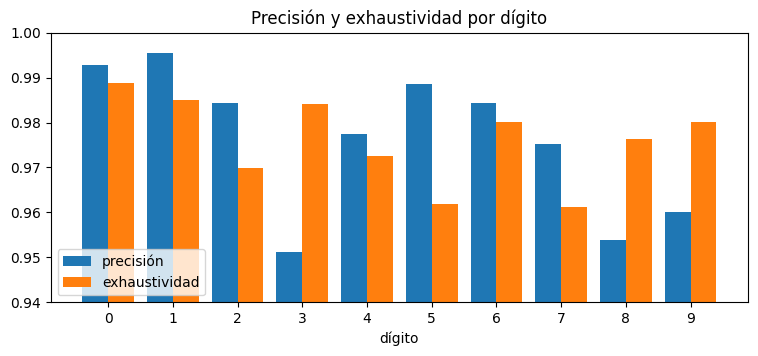

In [4]:
print(f"{'dígito':>6s} {'precisión':>10s} {'exhaustividad':>14s} {'F1':>8s} {'soporte':>8s}")
for c in torch.argsort(f1).tolist():
    print(f"{c:6d} {precision[c]:10.4f} {exhaustividad[c]:14.4f} {f1[c]:8.4f} {int(soporte[c]):8d}")

fig, eje = plt.subplots(figsize=(9, 3.5))
ancho = 0.4
eje.bar(torch.arange(10) - ancho / 2, precision, ancho, label="precisión")
eje.bar(torch.arange(10) + ancho / 2, exhaustividad, ancho, label="exhaustividad")
eje.set_xticks(range(10))
eje.set_xlabel("dígito")
eje.set_ylim(0.94, 1.0)
eje.legend(loc="lower left")
eje.set_title("Precisión y exhaustividad por dígito")
plt.show()

El 8 tiene el peor $F_1$, 0.965, pero no por lo que uno pensaría: su exhaustividad es buena (encuentra el 97.6% de los 8) y lo que falla es la precisión, 0.954. El modelo dice "8" demasiado seguido: uno de cada 20 de sus "8" es otro dígito. Al 3 y al 9 les pasa lo mismo. El 7 y el 5 son el caso contrario: cuando el modelo dice 7 casi siempre acierta (precisión 0.975), pero se le escapa casi el 4% de los 7 (exhaustividad 0.961). Son dos fallas distintas, con remedios distintos, que la exactitud de 97.62% junta en un solo número.

## 4. Detrás de la matriz de confusión

Made With ML recomienda mirar los ejemplos de cada casilla para la clase que interese: los verdaderos positivos muestran lo que el modelo hace bien, los falsos positivos pueden ser etiquetas que conviene revisar, y los falsos negativos muestran dónde le falta aprender. Lo hacemos con el dígito de menor $F_1$.

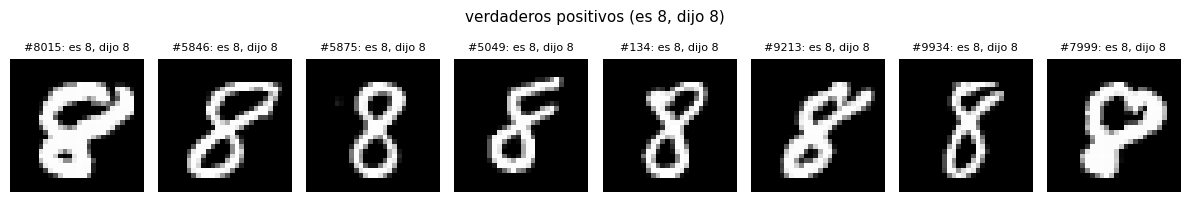

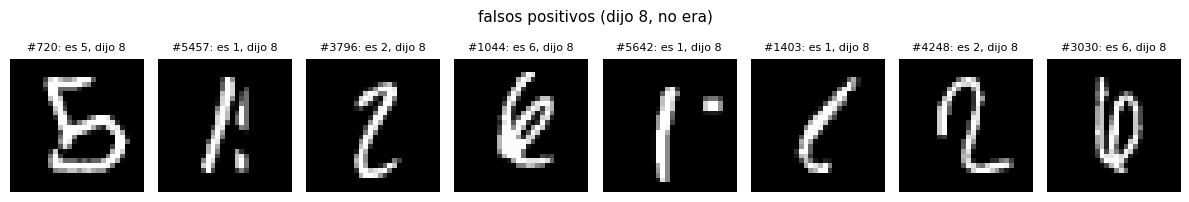

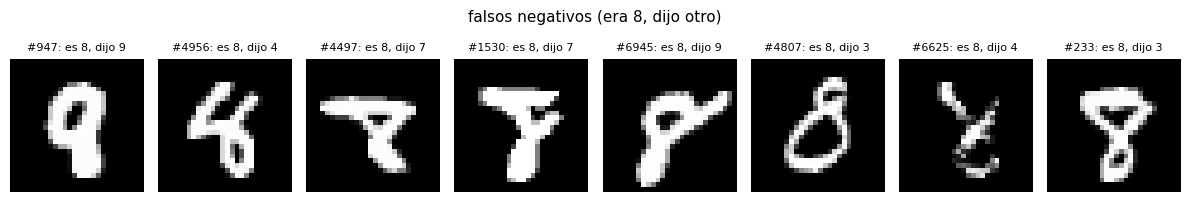

casillas del 8: VP = 951, FP = 46, FN = 23
a qué dígitos fueron sus falsos negativos: {3: 8, 4: 4, 6: 3, 7: 2, 9: 6}
de qué dígitos vinieron sus falsos positivos: {0: 3, 1: 7, 2: 11, 3: 3, 5: 8, 6: 7, 7: 5, 9: 2}


In [5]:
peor = int(torch.argmin(f1))
casillas = {
    f"verdaderos positivos (es {peor}, dijo {peor})": (y_prueba == peor) & (prediccion == peor),
    f"falsos positivos (dijo {peor}, no era)": (y_prueba != peor) & (prediccion == peor),
    f"falsos negativos (era {peor}, dijo otro)": (y_prueba == peor) & (prediccion != peor),
}
for titulo, mascara in casillas.items():
    indices = torch.nonzero(mascara).squeeze(1)
    # los más confiados primero: la probabilidad que el modelo le dio a su predicción
    indices = indices[torch.argsort(probabilidades[indices].max(dim=1).values, descending=True)][:8]
    fig, ejes = plt.subplots(1, 8, figsize=(12, 2.1))
    for eje, i in zip(ejes, indices.tolist()):
        eje.imshow(X_prueba[i, 0], cmap="gray")
        eje.set_title(f"#{i}: es {y_prueba[i].item()}, dijo {prediccion[i].item()}", fontsize=8)
    for eje in ejes:
        eje.axis("off")
    fig.suptitle(titulo, fontsize=11)
    plt.tight_layout()
    plt.show()
print(f"casillas del {peor}: VP = {int(vp[peor])}, FP = {int(fp[peor])}, FN = {int(fn[peor])}")
print("a qué dígitos fueron sus falsos negativos:", {d: int(confusion[peor, d]) for d in range(10) if d != peor and confusion[peor, d] > 0})
print("de qué dígitos vinieron sus falsos positivos:", {d: int(confusion[d, peor]) for d in range(10) if d != peor and confusion[d, peor] > 0})

Los falsos positivos del 8 vienen de casi todos los dígitos, sobre todo del 2 (11), el 5 (8), el 1 y el 6 (7 cada uno). En las imágenes se ve por qué: son dígitos con un lazo o un trazo que se cruza, como los 2 con rulo (#3796, #4248) o el 1 con una marca al lado (#5457). Varios se leen sin problema, y ahí el error es del modelo. Los falsos negativos, en cambio, se concentran en el 3 (8) y el 9 (6), y algunos son dudosos incluso para una persona: #947 parece un 9, y #4497 y #1530, con su barra arriba, parecen un 7. Esos son candidatos a etiqueta equivocada, y la sección 6 los busca de forma sistemática.

## 5. Confianza: calibración

Un modelo está **calibrado** si, entre todas las predicciones que hace con 80% de confianza, acierta el 80%. Made With ML advierte que las redes modernas no suelen estarlo (cita a Guo y otros, 2017: *On Calibration of Modern Neural Networks*), y que hay que calibrarlas antes de usar sus probabilidades como confianza.

Para medirlo se agrupan las predicciones por confianza en 10 intervalos y se compara, en cada uno, la confianza media con la exactitud. El **error de calibración esperado** (ECE) es el promedio de esas diferencias, ponderado por cuántas predicciones cae en cada intervalo:

$$\text{ECE} = \sum_{b=1}^{10} \frac{n_b}{n} \,\big|\, \text{exactitud}_b - \text{confianza}_b \,\big|$$

In [6]:
def calibracion(probabilidades, y, intervalos=10):
    confianza, prediccion = probabilidades.max(dim=1)
    acierto = (prediccion == y).float()
    bordes = torch.linspace(0, 1, intervalos + 1)
    filas, ece = [], 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        en = (confianza > a) & (confianza <= b)
        if en.any():
            filas.append((a.item(), b.item(), en.sum().item(), confianza[en].mean().item(), acierto[en].mean().item()))
            ece += en.float().mean().item() * abs(acierto[en].mean().item() - confianza[en].mean().item())
    return filas, ece


filas, ece = calibracion(probabilidades, y_prueba)
print(f"{'confianza':>12s} {'imágenes':>9s} {'conf. media':>12s} {'exactitud':>10s}")
for a, b, n, conf, exact in filas:
    print(f"  {a:.1f} a {b:.1f} {n:9d} {conf:12.3f} {exact:10.3f}")
print(f"\nECE: {ece:.4f}")

   confianza  imágenes  conf. media  exactitud
  0.2 a 0.3         1        0.298      0.000
  0.3 a 0.4         7        0.373      0.429
  0.4 a 0.5         9        0.469      0.444
  0.5 a 0.6        69        0.546      0.536
  0.6 a 0.7        67        0.643      0.582
  0.7 a 0.8        61        0.758      0.639
  0.8 a 0.9       144        0.860      0.778
  0.9 a 1.0      9642        0.998      0.988

ECE: 0.0115


En todos los intervalos con suficientes imágenes la exactitud queda por debajo de la confianza: el modelo está **sobreconfiado**. En el intervalo más alto, que reúne el 96% de las predicciones, dice en promedio 99.8% y acierta 98.8%; entre 0.8 y 0.9 dice 86% y acierta 78%. El ECE es 0.0115: en promedio, la confianza exagera la exactitud en algo más de un punto.

El remedio que recomienda Made With ML es el **escalado de temperatura** (Guo y otros, 2017): dividir todos los logits por un número $T > 0$ antes del softmax. Con $T > 1$ las probabilidades se suavizan hacia el reparto parejo; con $T < 1$ se afilan. Dividir todos los logits de una imagen por el mismo número no cambia cuál es el mayor, así que **ninguna predicción cambia**: solo cambia la confianza. $T$ se ajusta minimizando la entropía cruzada en la validación, con LBFGS como en `05-profundizacion/04_ajuste_polinomial_y_sobreajuste` del módulo 1.

temperatura ajustada en validación: T = 1.68
ECE en la prueba:        0.0115 sin escalar   0.0028 con T
pérdida en la prueba:    0.1019 sin escalar   0.0830 con T
¿cambió alguna predicción? False


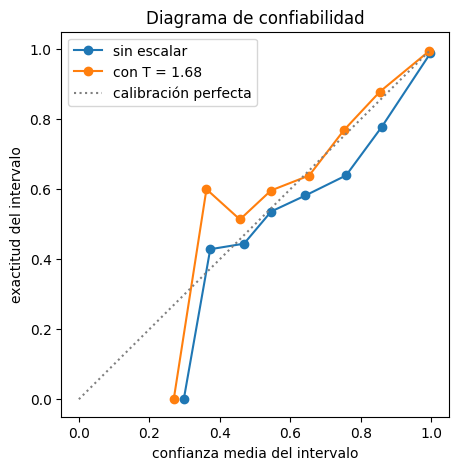

In [7]:
with torch.no_grad():
    logits_validacion = modelo(X_validacion)

temperatura = torch.ones(1, requires_grad=True)
lbfgs = torch.optim.LBFGS([temperatura], lr=0.1, max_iter=100)


def cierre():
    lbfgs.zero_grad()
    perdida = F.cross_entropy(logits_validacion / temperatura, y_validacion)
    perdida.backward()
    return perdida


lbfgs.step(cierre)
T = temperatura.item()
calibradas = (logits_prueba / T).softmax(dim=1)
_, ece_calibrado = calibracion(calibradas, y_prueba)
print(f"temperatura ajustada en validación: T = {T:.2f}")
print(f"ECE en la prueba:        {ece:.4f} sin escalar   {ece_calibrado:.4f} con T")
print(f"pérdida en la prueba:    {F.cross_entropy(logits_prueba, y_prueba):.4f} sin escalar   {F.cross_entropy(logits_prueba / T, y_prueba):.4f} con T")
print("¿cambió alguna predicción?", not torch.equal(calibradas.argmax(dim=1), prediccion))

fig, eje = plt.subplots(figsize=(5, 5))
for probs, etiqueta in [(probabilidades, "sin escalar"), (calibradas, f"con T = {T:.2f}")]:
    filas_b, _ = calibracion(probs, y_prueba)
    eje.plot([f[3] for f in filas_b], [f[4] for f in filas_b], marker="o", label=etiqueta)
eje.plot([0, 1], [0, 1], color="gray", linestyle=":", label="calibración perfecta")
eje.set_xlabel("confianza media del intervalo")
eje.set_ylabel("exactitud del intervalo")
eje.set_title("Diagrama de confiabilidad")
eje.legend()
plt.show()

La temperatura óptima es 1.68: el modelo exageraba sus logits en ese factor. Con ella el ECE en la prueba baja de 0.0115 a 0.0028, a la cuarta parte, la pérdida baja de 0.102 a 0.083, y ninguna de las 10.000 predicciones cambia. En el diagrama, la curva calibrada queda mucho más cerca de la diagonal en los intervalos altos, que son casi todas las predicciones. En los intervalos bajos las dos curvas saltan porque tienen muy pocas imágenes, entre 1 y unas 70.

## 6. Confianza: etiquetas sospechosas

La confianza también sirve para revisar los datos. Made With ML usa la librería `cleanlab`, que implementa el **aprendizaje confiado** (*confident learning*) de Northcutt, Jiang y Chuang (2021). Su idea central cabe en pocas líneas:

1. Para cada clase $j$, el **umbral** $t_j$ es la probabilidad media que el modelo le da a $j$ en los ejemplos etiquetados $j$. Mide cuán seguro suele estar el modelo cuando acierta esa clase.
2. Un ejemplo etiquetado $i$ es **sospechoso** si el modelo le da a otra clase $j$ una probabilidad de al menos $t_j$: está tan seguro de $j$ como suele estarlo con los $j$ de verdad.
3. Los sospechosos se ordenan por la probabilidad que el modelo le da a su etiqueta, de menor a mayor.

Para que funcione, las probabilidades tienen que venir de un modelo que no vio esos ejemplos al entrenar. La prueba cumple esa condición.

umbral por clase: [0.985, 0.973, 0.967, 0.98, 0.969, 0.956, 0.978, 0.957, 0.972, 0.975]
ejemplos sospechosos: 67 de 10000


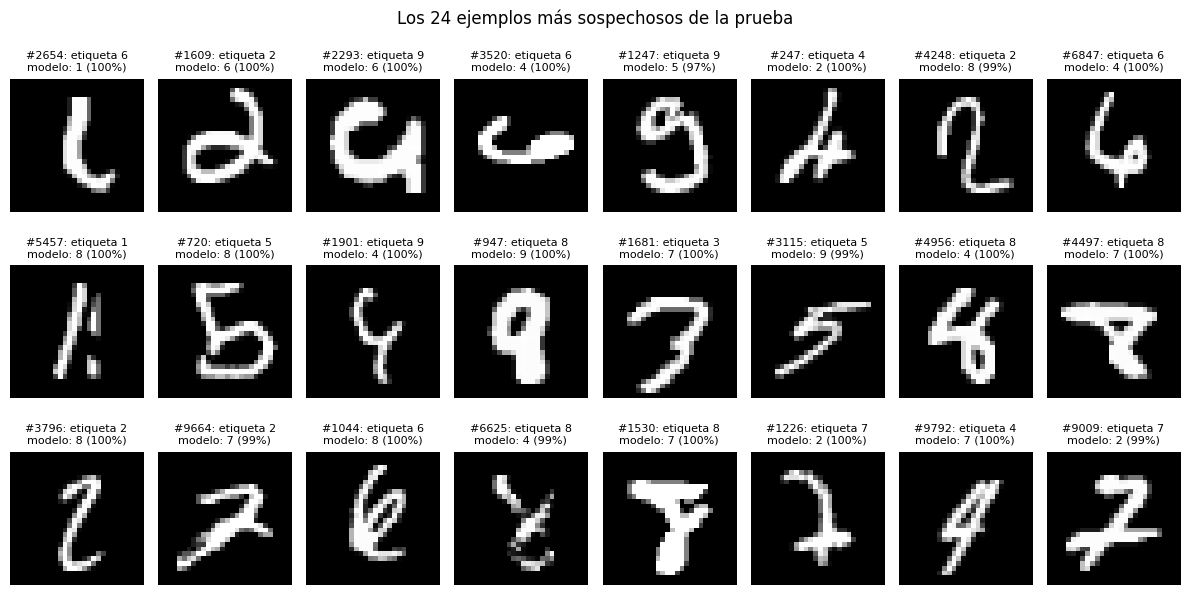

In [8]:
umbrales = torch.stack([probabilidades[y_prueba == j, j].mean() for j in range(10)])
print("umbral por clase:", [round(t, 3) for t in umbrales.tolist()])

supera = probabilidades >= umbrales                     # (10000, 10): ¿supera el umbral de cada clase?
supera[torch.arange(len(y_prueba)), y_prueba] = False   # la clase de su propia etiqueta no cuenta
sospechosos = torch.nonzero(supera.any(dim=1)).squeeze(1)
sospechosos = sospechosos[torch.argsort(probabilidades[sospechosos, y_prueba[sospechosos]])]
print(f"ejemplos sospechosos: {len(sospechosos)} de {len(y_prueba)}")

fig, ejes = plt.subplots(3, 8, figsize=(12, 6.3))
for eje, i in zip(ejes.flat, sospechosos[:24].tolist()):
    eje.imshow(X_prueba[i, 0], cmap="gray")
    eje.set_title(f"#{i}: etiqueta {y_prueba[i].item()}\nmodelo: {prediccion[i].item()} ({probabilidades[i].max():.0%})", fontsize=8)
    eje.axis("off")
plt.suptitle("Los 24 ejemplos más sospechosos de la prueba")
plt.tight_layout()
plt.show()

El método marca 67 de las 10.000 imágenes. Mirando las 24 primeras se distinguen tres tipos:

- **etiquetas que parecen equivocadas**: #2654, con etiqueta 6, se lee como un 1 o una L; #1681, con etiqueta 3, se ve como un 7; #1901, con etiqueta 9, parece un 4;
- **dígitos ambiguos**, que dos personas podrían leer distinto: #4497 y #1530 (etiqueta 8, con una barra arriba como un 7), #9664 y #9009 (¿2 o 7?);
- **errores del modelo**: #4248 y #3796 son 2 bien escritos, y #1247 es un 9 claro, y el modelo los clasifica mal con seguridad.

Northcutt, Athalye y Mueller (2021, *Pervasive Label Errors in Test Sets Destabilize Machine Learning Benchmarks*) hicieron este ejercicio con revisión humana: el aprendizaje confiado marcó 100 candidatas en la prueba de MNIST, y las personas confirmaron 15 como etiquetas equivocadas, el 0.15% del conjunto. Son pocas, pero los mejores modelos tienen 0.23% de error: en ese nivel, una parte de lo que se cuenta como error del modelo es error de la etiqueta.

## 7. Rebanadas

Una **rebanada** (*slice*) es un subconjunto de los datos definido por alguna característica: en la lección de Made With ML, los textos cortos o los que mencionan ciertas palabras. Una exactitud global alta puede esconder una rebanada donde el modelo es mucho peor, y si esa rebanada corresponde a un grupo de personas, el modelo las trata distinto.

Las imágenes de MNIST no traen más información que la etiqueta, así que calculamos características a partir de los píxeles:

- **tinta**: la suma de las intensidades, que separa trazos finos de gruesos;
- **altura**: cuántas filas ocupa el dígito. La página de MNIST dice que cada dígito se escaló hasta caber en una caja de 20×20, así que la mayoría mide 20 de alto;
- **inclinación**: cuánto se corre el trazo hacia la derecha por cada fila que baja (el momento $\mu_{11} / \mu_{02}$). Positiva es un trazo que baja hacia la derecha, como `\`; negativa, uno que baja hacia la izquierda, como `/`, la inclinación habitual de la escritura a mano.

In [9]:
pixeles = X_prueba[:, 0] * DESVIACION + MEDIA            # de vuelta a intensidades entre 0 y 1
filas_idx, columnas_idx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")

tinta = pixeles.sum(dim=(1, 2))
con_tinta = (pixeles > 0).any(dim=2)                         # (10000, 28): ¿la fila tiene algún píxel?
filas_con_tinta = torch.where(con_tinta, torch.arange(28), -1)
altura = filas_con_tinta.max(dim=1).values - torch.where(con_tinta, torch.arange(28), 99).min(dim=1).values + 1
centro_fila = (pixeles * filas_idx).sum(dim=(1, 2)) / tinta
centro_columna = (pixeles * columnas_idx).sum(dim=(1, 2)) / tinta
dy = filas_idx - centro_fila[:, None, None]
dx = columnas_idx - centro_columna[:, None, None]
inclinacion = (pixeles * dy * dx).sum(dim=(1, 2)) / (pixeles * dy ** 2).sum(dim=(1, 2))

print("altura del dígito:", {h: n for h, n in enumerate(torch.bincount(altura).tolist()) if n > 0})

altura del dígito: {10: 3, 11: 2, 12: 19, 13: 7, 14: 70, 15: 26, 16: 158, 17: 68, 18: 316, 19: 117, 20: 9214}


In [10]:
def rebanada(nombre, mascara):
    n = int(mascara.sum())
    error = (~acierto[mascara]).float().mean().item()
    print(f"{nombre:44s} {n:6d} {error:8.2%}")


q_tinta = torch.quantile(tinta, torch.tensor([0.1, 0.9]))
q_incl = torch.quantile(inclinacion, torch.tensor([0.1, 0.9]))
print(f"{'rebanada':44s} {'imágenes':>6s} {'error':>8s}")
rebanada("todas", torch.ones_like(acierto))
rebanada("trazo fino (el 10% con menos tinta)", tinta <= q_tinta[0])
rebanada("trazo fino, sin contar los 1", (tinta <= q_tinta[0]) & (y_prueba != 1))
rebanada("trazo grueso (el 10% con más tinta)", tinta >= q_tinta[1])
rebanada("más bajo que la caja (altura < 20)", altura < 20)
rebanada("inclinado como / (el 10% más)", inclinacion <= q_incl[0])
rebanada("inclinado como \\ (el 10% más)", inclinacion >= q_incl[1])
print(f"\ncuántos 1 hay en la rebanada de trazo fino: {int(((tinta <= q_tinta[0]) & (y_prueba == 1)).sum())} de {int((tinta <= q_tinta[0]).sum())}")

rebanada                                     imágenes    error
todas                                         10000    2.38%
trazo fino (el 10% con menos tinta)            1000    3.80%
trazo fino, sin contar los 1                    342    8.48%
trazo grueso (el 10% con más tinta)            1000    2.10%
más bajo que la caja (altura < 20)              786    3.69%
inclinado como / (el 10% más)                  1000    3.40%
inclinado como \ (el 10% más)                  1000    4.60%

cuántos 1 hay en la rebanada de trazo fino: 658 de 1000


La rebanada de trazo fino tiene 3.80% de error, un poco más que el total. Pero 658 de sus 1000 imágenes son 1, el dígito más fácil, que casi siempre tiene poca tinta. Sin ellos, los 342 dígitos restantes de trazo fino tienen 8.48% de error, más de tres veces el promedio. Una rebanada mezcla varias cosas, y su composición puede esconder justo lo que se busca.

Las otras rebanadas también rinden peor que el promedio: los dígitos que no llenan la caja de 20 píxeles de alto (3.69%) y, sobre todo, los inclinados como `\` (4.60%), una inclinación poco común en la escritura que el modelo vio poco al entrenar. Los de trazo grueso, en cambio, van mejor (2.10%).

### Una rebanada que nadie definió: quién escribió cada dígito

La página oficial de MNIST describe así el conjunto de prueba: las primeras 5000 imágenes vienen del conjunto de entrenamiento original de NIST, escrito por empleados de la Oficina del Censo de Estados Unidos, y las últimas 5000 del conjunto de prueba original, escrito por estudiantes de secundaria. Agrega que las primeras 5000 son más limpias y fáciles que las últimas.

En 2019, Chhavi Yadav y Léon Bottou reconstruyeron el origen de cada imagen de MNIST en NIST (*Cold Case: The Lost MNIST Digits*). Encontraron lo contrario: las primeras 5001 imágenes de la prueba fueron escritas por estudiantes de secundaria, y las 4999 siguientes por solo 48 empleados del Censo, con una letra mucho más limpia.

¿Quién tiene razón? El modelo puede servir de árbitro: si una mitad es más difícil, tendrá más errores.

primeras 5001 (estudiantes, según Yadav y Bottou)           162 errores = 3.24% ± 0.50%
últimas 4999 (empleados del Censo, según Yadav y Bottou)     76 errores = 1.52% ± 0.35%


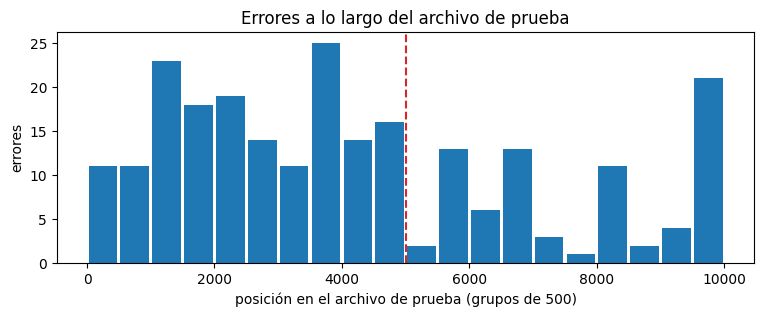

In [11]:
for nombre, tramo in [("primeras 5001 (estudiantes, según Yadav y Bottou)", slice(0, 5001)),
                      ("últimas 4999 (empleados del Censo, según Yadav y Bottou)", slice(5001, 10_000))]:
    errores = (~acierto[tramo]).sum().item()
    total = len(acierto[tramo])
    margen = 2 * math.sqrt((errores / total) * (1 - errores / total) / total)
    print(f"{nombre:58s} {errores:4d} errores = {errores / total:.2%} ± {margen:.2%}")

errores_por_tramo = (~acierto).view(20, 500).sum(dim=1)
plt.figure(figsize=(9, 3))
plt.bar(torch.arange(20) * 500 + 250, errores_por_tramo, width=450)
plt.axvline(5001, color="tab:red", linestyle="--")
plt.xlabel("posición en el archivo de prueba (grupos de 500)")
plt.ylabel("errores")
plt.title("Errores a lo largo del archivo de prueba")
plt.show()

La primera mitad tiene 162 errores y la segunda 76: más del doble. Los intervalos de confianza no se tocan, así que no es ruido. Los datos dan la razón a Yadav y Bottou: las imágenes difíciles están al principio, no al final. El gráfico muestra que no se debe a un tramo puntual: los diez grupos de 500 de la primera mitad tienen entre 11 y 25 errores, y en la segunda, seis de los diez tienen 6 o menos. El último grupo, con 21, recuerda que entre los 48 empleados del Censo también hay letras difíciles.

El origen de los datos es una rebanada que no aparece en ninguna columna: el archivo no dice quién escribió cada dígito. Una consecuencia práctica: el error medido solo en las primeras o solo en las últimas 5000 imágenes no se puede comparar con el medido en el conjunto completo.

## 8. Interpretabilidad

Made With ML usa LIME para ver qué palabras pesan en una predicción. La idea de LIME, y de SHAP, es medir la importancia de una parte de la entrada por lo que cambia la predicción cuando esa parte falta. En imágenes, la versión más directa es la **oclusión**: tapar un cuadrado de la imagen con fondo, ver cuánto baja la probabilidad de la clase predicha, y repetir moviendo el cuadrado por toda la imagen.

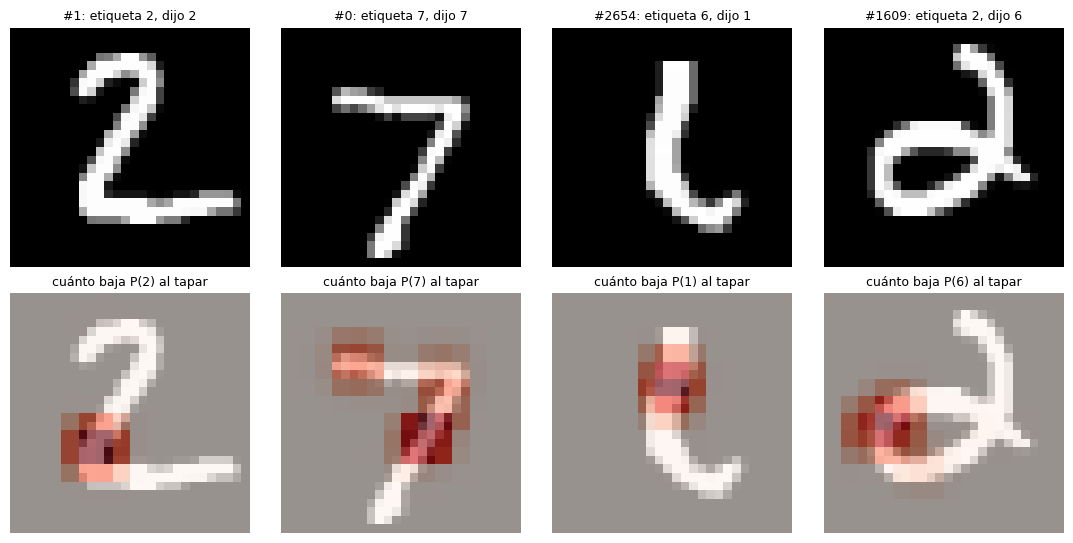

In [12]:
def oclusion(imagen, lado=6, paso=2):
    with torch.no_grad():
        p = modelo(imagen[None]).softmax(dim=1)[0]
    clase = int(p.argmax())
    tapadas, posiciones = [], []
    for fila in range(0, 28 - lado + 1, paso):
        for columna in range(0, 28 - lado + 1, paso):
            copia = imagen.clone()
            copia[:, fila:fila + lado, columna:columna + lado] = FONDO
            tapadas.append(copia)
            posiciones.append((fila, columna))
    with torch.no_grad():
        caida = p[clase] - modelo(torch.stack(tapadas)).softmax(dim=1)[:, clase]
    mapa, cuenta = torch.zeros(28, 28), torch.zeros(28, 28)
    for (fila, columna), c in zip(posiciones, caida):
        mapa[fila:fila + lado, columna:columna + lado] += c
        cuenta[fila:fila + lado, columna:columna + lado] += 1
    return clase, mapa / cuenta


ejemplos = [int(torch.nonzero(acierto & (y_prueba == d))[0]) for d in (2, 7)] + sospechosos[:2].tolist()
fig, ejes = plt.subplots(2, 4, figsize=(11, 5.5))
for k, i in enumerate(ejemplos):
    clase, mapa = oclusion(X_prueba[i])
    ejes[0, k].imshow(X_prueba[i, 0], cmap="gray")
    ejes[0, k].set_title(f"#{i}: etiqueta {y_prueba[i].item()}, dijo {clase}", fontsize=9)
    ejes[1, k].imshow(X_prueba[i, 0], cmap="gray")
    ejes[1, k].imshow(mapa, cmap="Reds", alpha=0.6, vmin=0, vmax=max(mapa.max().item(), 1e-6))
    ejes[1, k].set_title(f"cuánto baja P({clase}) al tapar", fontsize=9)
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

En el 2 (#1), lo que más pesa es la esquina inferior izquierda, donde el trazo dobla para formar la base: sin ella podría ser un 7 o un 1. En el 7 (#0), el extremo izquierdo de la barra y el tramo medio del trazo vertical. En #2654, el modelo dijo 1 mirando el trazo vertical, y tapar su parte de arriba es lo que más le baja la probabilidad de 1. En #1609, el 2 con un lazo, el modelo dijo 6 por el lazo: tapar su lado izquierdo es lo que más seguridad le quita.

La oclusión no explica el razonamiento del modelo, pero dice dónde mirar, y sirve para detectar atajos: un modelo que se apoyara en una marca del borde o en el fondo mostraría manchas fuera del dígito.

## 9. Pruebas de comportamiento

Las pruebas de comportamiento tratan al modelo como una caja negra y le hacen preguntas concretas. Made With ML las toma de *CheckList* (Ribeiro y otros, 2020), que propone tres tipos:

- **invariancia**: cambios que no deberían cambiar la predicción;
- **direccionales**: cambios que deberían cambiarla, en una dirección conocida;
- **funcionalidad mínima**: pares simples de entrada y salida que el modelo tiene que acertar.

### Invariancia

Un dígito movido unos píxeles, girado unos grados o escrito con un trazo un poco más grueso sigue siendo el mismo dígito. Medimos qué fracción de las 10.000 predicciones de la prueba cambia con cada transformación:

predicciones que cambian:


  mover 1 píxel        4.4%  (promedio de arriba, abajo, izquierda y derecha)


  mover 2 píxeles     18.3%  (promedio de arriba, abajo, izquierda y derecha)


  mover 3 píxeles     42.6%  (promedio de arriba, abajo, izquierda y derecha)


  girar 10°            3.4%  (promedio de los dos sentidos)


  girar 20°           11.3%  (promedio de los dos sentidos)


  engrosar el trazo   10.1%


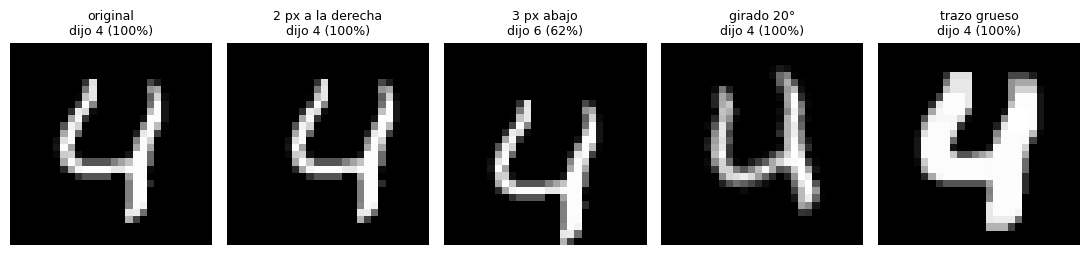

In [13]:
def mover(X, dy, dx):
    lienzo = F.pad(X, (4, 4, 4, 4), value=FONDO)
    return torch.roll(lienzo, shifts=(dy, dx), dims=(2, 3))[:, :, 4:32, 4:32]


def girar(X, grados):
    a = math.radians(grados)
    theta = torch.tensor([[math.cos(a), -math.sin(a), 0.0], [math.sin(a), math.cos(a), 0.0]]).expand(len(X), 2, 3)
    grilla = F.affine_grid(theta, list(X.shape), align_corners=False)
    return F.grid_sample(X - FONDO, grilla, align_corners=False) + FONDO   # lo que entra desde fuera es fondo


def engrosar(X):
    return F.max_pool2d(X, kernel_size=3, stride=1, padding=1)          # cada píxel toma el máximo de sus vecinos


def cambian(X_transformado):
    with torch.no_grad():
        return (modelo(X_transformado).argmax(dim=1) != prediccion).float().mean().item()


print("predicciones que cambian:")
for d in [1, 2, 3]:
    promedio = sum(cambian(mover(X_prueba, dy, dx)) for dy, dx in [(d, 0), (-d, 0), (0, d), (0, -d)]) / 4
    nombre = f"mover {d} píxel" + ("es" if d > 1 else "")
    print(f"  {nombre:18s} {promedio:6.1%}  (promedio de arriba, abajo, izquierda y derecha)")
for grados in [10, 20]:
    promedio = (cambian(girar(X_prueba, grados)) + cambian(girar(X_prueba, -grados))) / 2
    print(f"  {f'girar {grados}°':18s} {promedio:6.1%}  (promedio de los dos sentidos)")
print(f"  {'engrosar el trazo':18s} {cambian(engrosar(X_prueba)):6.1%}")

i = int(torch.nonzero(acierto & (y_prueba == 4))[0])
variantes = {"original": X_prueba[i:i + 1], "2 px a la derecha": mover(X_prueba[i:i + 1], 0, 2),
             "3 px abajo": mover(X_prueba[i:i + 1], 3, 0), "girado 20°": girar(X_prueba[i:i + 1], 20),
             "trazo grueso": engrosar(X_prueba[i:i + 1])}
fig, ejes = plt.subplots(1, 5, figsize=(11, 2.6))
for eje, (nombre, x) in zip(ejes, variantes.items()):
    with torch.no_grad():
        p = modelo(x).softmax(dim=1)[0]
    eje.imshow(x[0, 0], cmap="gray")
    eje.set_title(f"{nombre}\ndijo {int(p.argmax())} ({p.max():.0%})", fontsize=9)
    eje.axis("off")
plt.tight_layout()
plt.show()

Mover el dígito un píxel cambia el 4.4% de las predicciones, casi el doble de la tasa de error del modelo. Con 2 píxeles cambia el 18%, y con 3 cerca de la mitad. Para una persona, el 4 movido 3 píxeles hacia abajo es idéntico al original; el modelo lo lee como 6. Girar y engrosar le afectan menos, pero tampoco le son indiferentes.

La razón es la de `04-clasificacion-de-imagenes/02_experimentos_con_mnist`: después de `Flatten`, cada píxel es una entrada separada, sin relación con sus vecinos. Mover la imagen es, para la red, cambiar casi todas las entradas a la vez. En MNIST no se nota porque todos los dígitos vienen centrados por su centro de masa. Las redes convolucionales, que aplican los mismos pesos en todas las posiciones, resuelven buena parte de este problema.

### Direccional

Si a un 1 se le agrega un trazo horizontal arriba, hacia la izquierda, queda un 7. Lo hacemos con los 1 de la prueba que el modelo clasificó bien: en la fila más alta del trazo dibujamos una barra de 2 píxeles de grosor y 10 de largo.

unos modificados: 1118
  el modelo dice 1:  344  (30.8%)
  el modelo dice 2:  357  (31.9%)
  el modelo dice 3:  195  (17.4%)
  el modelo dice 6:    1  (0.1%)
  el modelo dice 7:  113  (10.1%)
  el modelo dice 8:  108  (9.7%)


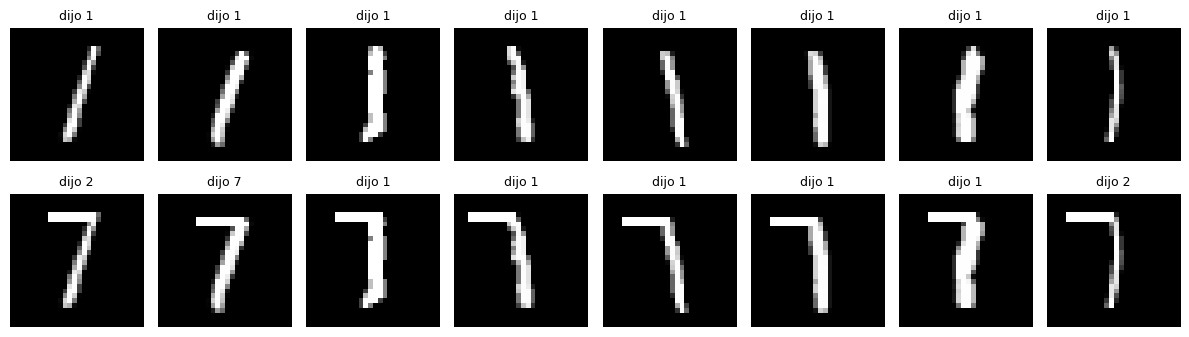

In [14]:
unos = torch.nonzero((y_prueba == 1) & acierto).squeeze(1)
sietes = (X_prueba[unos] * DESVIACION + MEDIA).clone()                  # intensidades entre 0 y 1
for k in range(len(sietes)):
    imagen = sietes[k, 0]
    fila_superior = int(torch.nonzero(imagen.max(dim=1).values > 0.5).min())
    columna_derecha = int(torch.nonzero(imagen[fila_superior] > 0.5).max())
    imagen[fila_superior:fila_superior + 2, max(0, columna_derecha - 9):columna_derecha + 1] = 1.0
sietes = (sietes - MEDIA) / DESVIACION

with torch.no_grad():
    dicho = modelo(sietes).argmax(dim=1)
print(f"unos modificados: {len(unos)}")
for d, n in enumerate(torch.bincount(dicho, minlength=10).tolist()):
    if n:
        print(f"  el modelo dice {d}: {n:4d}  ({n / len(unos):.1%})")

fig, ejes = plt.subplots(2, 8, figsize=(12, 3.6))
for k in range(8):
    ejes[0, k].imshow(X_prueba[unos[k], 0], cmap="gray")
    ejes[0, k].set_title("dijo 1", fontsize=9)
    ejes[1, k].imshow(sietes[k, 0], cmap="gray")
    ejes[1, k].set_title(f"dijo {int(dicho[k])}", fontsize=9)
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

Solo el 10.1% de los 1 modificados pasa a 7. El resto sigue siendo 1 (30.8%) o pasa a 2 (31.9%), 3 u 8, aunque a simple vista son 7. Es una falla de dirección: el modelo no aprendió que la barra de arriba es lo que separa un 7 de un 1. Los 7 de MNIST suelen tener barras más largas y trazos más inclinados que estos, y el modelo aprendió esa forma típica más que la regla. Una prueba así dice más sobre lo que aprendió el modelo que mil imágenes de prueba parecidas a las de entrenamiento.

### Funcionalidad mínima

La prueba más simple: el promedio de todas las imágenes de entrenamiento de cada dígito es un dígito "de libro", borroso pero inconfundible, y el modelo tiene que acertar los diez. La acompañamos de una entrada que no es ningún dígito: una imagen vacía.

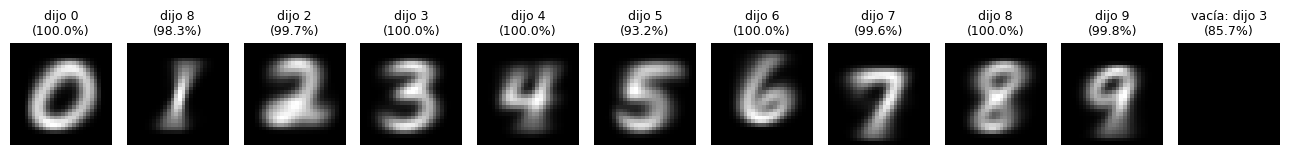

prototipos bien clasificados: 9 de 10


In [15]:
prototipos = torch.stack([X_entrenamiento[y_entrenamiento == d].mean(dim=0) for d in range(10)])
vacia = torch.full((1, 1, 28, 28), FONDO)
with torch.no_grad():
    p_prototipos = modelo(prototipos).softmax(dim=1)
    p_vacia = modelo(vacia).softmax(dim=1)[0]

fig, ejes = plt.subplots(1, 11, figsize=(13, 1.9))
for d in range(10):
    ejes[d].imshow(prototipos[d, 0], cmap="gray")
    ejes[d].set_title(f"dijo {int(p_prototipos[d].argmax())}\n({p_prototipos[d].max():.1%})", fontsize=9)
ejes[10].imshow(vacia[0, 0], cmap="gray", vmin=FONDO, vmax=2.8)
ejes[10].set_title(f"vacía: dijo {int(p_vacia.argmax())}\n({p_vacia.max():.1%})", fontsize=9)
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()
print("prototipos bien clasificados:", int((p_prototipos.argmax(dim=1) == torch.arange(10)).sum()), "de 10")

Nueve de diez. El que falla es el 1: el promedio de los 1 es una mancha ancha, porque cada 1 está inclinado en un ángulo distinto, y el modelo, que aprendió que un 1 es un trazo delgado, la lee como un 8 con 98% de seguridad. La imagen vacía es todavía más reveladora: el modelo dice 3 con 85.7% de confianza. Un clasificador con softmax siempre reparte el 100% entre sus diez clases y no tiene forma de decir "esto no es un dígito". Para detectar entradas que no se parecen a las de entrenamiento hace falta algo más que la salida del softmax (ejercicio 6).

## 10. Capacidad contra alineación

La última idea de la lección distingue dos cosas que solemos mezclar:

- la **capacidad** del modelo es qué tan bien hace la tarea medida por la función que optimiza: aquí, la entropía cruzada;
- la **alineación** es qué tan bien hace lo que de verdad queremos: aquí, acertar el dígito, medido con la exactitud.

Normalmente se mueven juntas. Cuando se separan, dicen algo. Miremos la historia de validación que anotamos al entrenar:

época  1: pérdida de validación 0.1440   exactitud 95.68%
época  2: pérdida de validación 0.1009   exactitud 97.06%
época  3: pérdida de validación 0.0853   exactitud 97.38%
época  4: pérdida de validación 0.0914   exactitud 97.35%
época  5: pérdida de validación 0.0912   exactitud 97.42%
época  6: pérdida de validación 0.0845   exactitud 97.61%
época  7: pérdida de validación 0.0970   exactitud 97.45%
época  8: pérdida de validación 0.0992   exactitud 97.41%
época  9: pérdida de validación 0.0976   exactitud 97.76%
época 10: pérdida de validación 0.1049   exactitud 97.53%


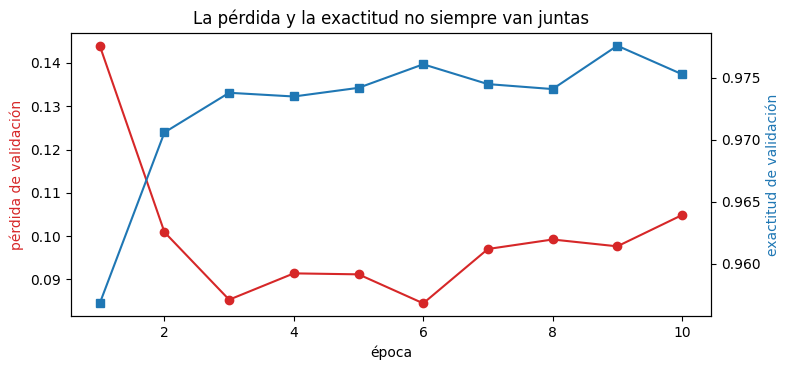

In [16]:
epocas = range(1, len(historia["pérdida"]) + 1)
for e, perdida, exactitud in zip(epocas, historia["pérdida"], historia["exactitud"]):
    print(f"época {e:2d}: pérdida de validación {perdida:.4f}   exactitud {exactitud:.2%}")

fig, eje = plt.subplots(figsize=(8, 3.8))
eje.plot(epocas, historia["pérdida"], marker="o", color="tab:red")
eje.set_xlabel("época")
eje.set_ylabel("pérdida de validación", color="tab:red")
eje2 = eje.twinx()
eje2.plot(epocas, historia["exactitud"], marker="s", color="tab:blue")
eje2.set_ylabel("exactitud de validación", color="tab:blue")
eje.set_title("La pérdida y la exactitud no siempre van juntas")
plt.tight_layout()
plt.show()

Hasta la época 3 las dos mejoran juntas. Después se separan: la pérdida de validación toca su mínimo en la época 6 (0.0845) y sube hasta 0.105 en la 10, mientras la exactitud se mantiene y alcanza su máximo en la época 9 (97.76%). Comparada con la época 3, la 9 tiene más pérdida (0.098 contra 0.085) y más exactitud (97.76% contra 97.38%).

¿Cómo puede el modelo acertar más y tener más pérdida? Porque la entropía cruzada castiga sobre todo los errores confiados (`02-entrenamiento/01_funciones_de_perdida_en_la_practica`, sección 6). A medida que entrena, el modelo se vuelve más seguro de todo: acierta algunas imágenes más, pero las que sigue errando las yerra con más confianza, y cada una de ellas suma mucho a la pérdida. Es la misma sobreconfianza que corrigió el escalado de temperatura en la sección 5. Made With ML lo resume así: una exactitud alta con una pérdida alta indica que el modelo falla muy mal en algunos datos.

## 11. Evaluar en producción

Todo lo anterior es evaluación **fuera de línea**, con datos guardados. La lección termina con la evaluación **en línea**, una vez que el modelo está en uso, cuando las etiquetas llegan tarde o no llegan, y hay que apoyarse en señales indirectas (correcciones de los usuarios, etiquetado manual de una muestra). Para comparar un modelo nuevo con el actual describe tres estrategias:

- **prueba A/B**: una parte del tráfico va al modelo nuevo y otra al actual, y se comparan los resultados con una prueba estadística;
- **despliegue canario**: el modelo nuevo atiende a un grupo pequeño de usuarios mientras el resto sigue con el actual, y se amplía si todo va bien;
- **modo sombra**: el modelo nuevo recibe todo el tráfico en paralelo pero sus respuestas no se muestran; es seguro, pero no recoge la reacción de los usuarios.

Las tres requieren infraestructura de despliegue, que queda fuera de estos notebooks.

## 12. Resumen

- La exactitud es una métrica **gruesa**. Las métricas **finas** (precisión, exhaustividad y $F_1$ por clase) dicen dónde falla el modelo y de qué forma: confundir un dígito con otro baja la exhaustividad del primero y la precisión del segundo.
- Mirar los ejemplos de cada casilla de la matriz de confusión distingue errores del modelo de etiquetas dudosas.
- Una red puede estar mal **calibrada**: aquí, demasiado confiada. El **escalado de temperatura** divide los logits por un número $T$ ajustado en la validación, corrige la calibración y no cambia ninguna predicción.
- El **aprendizaje confiado** usa un umbral por clase para encontrar ejemplos cuya etiqueta contradice con seguridad al modelo. En la prueba de MNIST encuentra dígitos mal etiquetados de verdad.
- Las **rebanadas** revelan subconjuntos donde el modelo es peor. Hay que fijarse en su composición: una rebanada dominada por una clase fácil esconde los errores de las demás.
- Los datos confirman a Yadav y Bottou: la primera mitad de la prueba de MNIST, escrita por estudiantes, tiene el doble de errores que la segunda, escrita por empleados del Censo. La página oficial lo dice al revés.
- Las **pruebas de comportamiento** encuentran fallas que la exactitud no muestra: este modelo cambia de opinión con un dígito movido 2 o 3 píxeles, no reconoce un 7 construido a partir de un 1, y asigna con seguridad un dígito a una imagen vacía.
- La pérdida (capacidad) puede empeorar mientras la exactitud (alineación) mejora: el modelo se vuelve más confiado en sus errores.

## Ejercicios

1. Calcula las métricas de la sección 2 con `average="weighted"` de `sklearn.metrics.precision_recall_fscore_support`, si tienes scikit-learn instalado, y comprueba que coinciden.
2. Repite la búsqueda de etiquetas sospechosas sobre el **entrenamiento**. Como el modelo vio esas imágenes, primero necesitas probabilidades fuera de muestra: divide el entrenamiento en 5 partes, entrena un modelo con 4 y predice la quinta, rotando. ¿Cuántos sospechosos encuentras en las 50.000 imágenes?
3. Agrega una rebanada por dígito y por tinta a la vez: los 9 con trazo fino. ¿Cuánto error tienen? ¿Se te ocurre por qué?
4. Repite las pruebas de invariancia con el modelo entrenado con desplazamientos de `01_depurar_un_modelo` (sección 9, paso 5). ¿Cuánto mejora la invariancia a los desplazamientos? ¿Y la de las rotaciones, que no entrenó?
5. Diseña otra prueba direccional: cerrar la parte de arriba de un 4 abierto para que parezca un 9, o agregarle una barra a un 0. ¿Qué tan seguido acierta el modelo la dirección esperada?
6. Pasa al modelo las imágenes de prueba de Fashion-MNIST (`datasets.FashionMNIST`), que no son dígitos. ¿Con qué confianza media predice? ¿Ayuda el escalado de temperatura a detectar que no son dígitos?